### 한국어 온라인 댓글 욕설 탐지 데이터셋
- 인터넷 주요 커뮤니티의 다양한 댓글을 전처리하여 욕설, 공격성, 인신공격 여부를 이진 분류용으로 수동 라벨링한 인공지능 윤리 가드레일 데이터셋
- https://github.com/2runo/Curse-detection-data?tab=readme-ov-file

In [14]:
import pandas as pd
import numpy as np
import random
import time
import datetime
import csv
import os
import torch
import subprocess
import torch.nn.functional as F
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm import tqdm
from sklearn.preprocessing import MultiLabelBinarizer  # 멀티라벨
from datasets import load_dataset
from torch.optim import AdamW
from transformers import pipeline
from transformers import AutoTokenizer
from transformers import AutoModelForSequenceClassification
from transformers import get_linear_schedule_with_warmup
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler
from torch.nn.utils.rnn import pad_sequence
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score, hamming_loss

In [2]:
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
REPO_DIR = DATA_DIR / "curse-detection"

if not REPO_DIR.exists():
    subprocess.run(['git', 'clone', 'https://github.com/2runo/Curse-detection-data', str(REPO_DIR)], check=True)
else:
    print(f'이미 저장소가 존재합니다. {REPO_DIR}')

이미 저장소가 존재합니다. /Users/juyeong/KDT/HomeWork/악성 댓글 탐지_Transformer/data/curse-detection


In [3]:
for p in REPO_DIR.iterdir():
    print(p.name)

LICENSE
dataset.txt
README.md
.git


In [4]:
REPO_DIR

PosixPath('/Users/juyeong/KDT/HomeWork/악성 댓글 탐지_Transformer/data/curse-detection')

In [5]:
train_file = REPO_DIR / "dataset.txt"

with train_file.open("r", encoding='utf-8') as f:
    for _ in range(3):
        print(f.readline().rstrip())

좌배 까는건 ㅇㅂ|1
집에 롱 패딩만 세 개다. 10년 더 입어야지 ㅋㅋ|0
 개소리야 니가 빨갱이를 옹호하고 드루킹을 ㅇㅇ짓이라고 말못해서 삐진거야 빨갱아|1


## 이진 분류로 악성 댓글 탐지하기

기존 셀 다음부터 실행합니다. `7_PLM.ipynb`의 토큰화 → DataLoader → AdamW 학습 → 평가 흐름을 사용합니다.
멀티라벨 인코딩 대신 **0: 일반 댓글, 1: 악성 댓글** 정수 라벨을 사용합니다.
모델은 한국어 사전학습 [KLUE BERT](https://huggingface.co/klue/bert-base)를 두 클래스 분류로 미세조정합니다.
출력 두 개에 softmax를 적용하며, 학습 손실은 교차 엔트로피입니다.

[데이터셋의 기준](https://github.com/2runo/Curse-detection-data)에 따른 욕설·비하 탐지 실험입니다.
모든 형태의 악성 댓글을 포괄하는 정답 시스템은 아니며, 문맥에 따라 오탐·누락이 발생할 수 있습니다.
첫 모델 실행에는 다운로드가 필요하고, 학습 시간은 장치에 따라 달라집니다.


In [6]:
# 기존 import 셀과 별도로 필요한 항목을 명시합니다.
from pathlib import Path
import json
import random
import time
import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
)
from torch.utils.data import TensorDataset, DataLoader
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import get_linear_schedule_with_warmup

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print("학습 장치:", DEVICE)


학습 장치: mps


## 1. 데이터 읽기와 중복 확인
댓글 안의 `|`를 보존하기 위해 마지막 구분자만 사용합니다. 동일 댓글이 서로 다른 split에 들어가는 것을 막고, 상충하는 라벨의 댓글은 제외합니다.


In [7]:
DATASET_PATH = REPO_DIR / "dataset.txt"
records = []
with DATASET_PATH.open(encoding="utf-8-sig") as f:
    for line_number, line in enumerate(f, start=1):
        line = line.rstrip("\r\n")
        if not line.strip():
            continue
        try:
            document, label = line.rsplit("|", 1)
            label = int(label.strip())
        except ValueError as exc:
            raise ValueError(f"{line_number}행의 댓글|라벨 형식을 확인하세요.") from exc
        if label not in (0, 1):
            raise ValueError(f"{line_number}행: 라벨은 0 또는 1이어야 합니다.")
        document = document.strip()
        if document:
            records.append({"document": document, "label": label})

df = pd.DataFrame(records)
if df.empty:
    raise ValueError("학습할 댓글이 없습니다.")
conflicting = df.groupby("document")["label"].nunique()
conflicting_texts = conflicting[conflicting > 1].index
conflict_count = int(df["document"].isin(conflicting_texts).sum())
df = df[~df["document"].isin(conflicting_texts)]
before_dedup = len(df)
df = df.drop_duplicates(subset="document").reset_index(drop=True)
print("읽은 댓글:", len(records))
print("라벨 충돌로 제외한 행:", conflict_count)
print("중복으로 제외한 행:", before_dedup - len(df))
print("사용할 댓글:", len(df))
print(df["label"].value_counts().sort_index().rename(index={0: "일반", 1: "악성"}))


읽은 댓글: 5825
라벨 충돌로 제외한 행: 0
중복으로 제외한 행: 4
사용할 댓글: 5821
label
일반    3779
악성    2042
Name: count, dtype: int64


In [8]:
# stratify: 각 split의 일반/악성 비율을 최대한 동일하게 유지합니다.
train_df, remaining_df = train_test_split(
    df, test_size=0.3, random_state=SEED, stratify=df["label"]
)
validation_df, test_df = train_test_split(
    remaining_df, test_size=0.5, random_state=SEED,
    stratify=remaining_df["label"],
)
train = Dataset.from_pandas(train_df.reset_index(drop=True), preserve_index=False)
validation = Dataset.from_pandas(validation_df.reset_index(drop=True), preserve_index=False)
test = Dataset.from_pandas(test_df.reset_index(drop=True), preserve_index=False)

print(train)
print(validation)
print(test)
for name, split in [("train", train), ("validation", validation), ("test", test)]:
    print(f"{name}: {len(split)}개, 악성 비율 {np.mean(split['label']):.1%}")
# 정수 개수로 나누므로 비율에는 반올림 오차가 있습니다.
assert not (set(train["document"]) & set(validation["document"]))
assert not (set(train["document"]) & set(test["document"]))
assert not (set(validation["document"]) & set(test["document"]))


Dataset({
    features: ['document', 'label'],
    num_rows: 4074
})
Dataset({
    features: ['document', 'label'],
    num_rows: 873
})
Dataset({
    features: ['document', 'label'],
    num_rows: 874
})
train: 4074개, 악성 비율 35.1%
validation: 873개, 악성 비율 35.1%
test: 874개, 악성 비율 35.1%


## 2. 토큰화와 DataLoader
라벨은 `[배치 크기]` 형태의 `torch.long`입니다. Mac 노트북에서도 동작하도록 `num_workers=0`을 사용합니다.


In [9]:
MODEL_NAME = "klue/bert-base"
MAX_LEN = 128
BATCH_SIZE = 8  # 메모리가 부족하면 4로 낮추세요.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode_texts(texts, labels, tokenizer, max_len=MAX_LEN):
    encoded = tokenizer(
        list(texts), add_special_tokens=True, truncation=True,
        max_length=max_len, padding="max_length", return_tensors="pt",
    )
    # 멀티라벨의 float multi-hot 대신, 0/1 정수 라벨을 사용합니다.
    return encoded["input_ids"], encoded["attention_mask"], torch.tensor(list(labels), dtype=torch.long)

train_inputs, train_mask, train_labels = encode_texts(train["document"], train["label"], tokenizer)
validation_inputs, validation_mask, validation_labels = encode_texts(validation["document"], validation["label"], tokenizer)
test_inputs, test_mask, test_labels = encode_texts(test["document"], test["label"], tokenizer)

train_data = TensorDataset(train_inputs, train_mask, train_labels)
validation_data = TensorDataset(validation_inputs, validation_mask, validation_labels)
test_data = TensorDataset(test_inputs, test_mask, test_labels)
loader_options = dict(batch_size=BATCH_SIZE, num_workers=0, pin_memory=DEVICE.type == "cuda")
train_dataloader = DataLoader(
    train_data, shuffle=True, generator=torch.Generator().manual_seed(SEED), **loader_options
)
validation_dataloader = DataLoader(validation_data, shuffle=False, **loader_options)
test_dataloader = DataLoader(test_data, shuffle=False, **loader_options)
batch = next(iter(train_dataloader))
print("input_ids:", batch[0].shape)
print("attention_mask:", batch[1].shape)
print("labels:", batch[2].shape, batch[2].dtype)


input_ids: torch.Size([8, 128])
attention_mask: torch.Size([8, 128])
labels: torch.Size([8]) torch.int64


## 3. 이진 분류 모델과 학습 설정
`single_label_classification`은 한 댓글에 하나의 클래스가 있는 분류입니다. 여기서는 클래스 수가 2이므로 이진 분류입니다. 새 분류 헤드의 가중치 초기화 안내는 정상이며, 다음 단계에서 학습합니다.


In [10]:
id2label = {0: "일반 댓글", 1: "악성 댓글"}
label2id = {label: idx for idx, label in id2label.items()}
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, problem_type="single_label_classification",
    id2label=id2label, label2id=label2id,
).to(DEVICE)

EPOCHS = 5
LEARNING_RATE = 2e-5
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
total_steps = len(train_dataloader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=int(total_steps * 0.1), num_training_steps=total_steps,
)
MODEL_DIR = PROJECT_DIR / "model" / "klue_bert_curse_binary"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print("학습 step:", total_steps)
print("모델 저장 위치:", MODEL_DIR.resolve())


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 12736.19it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: klue/bert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint

학습 step: 2550
모델 저장 위치: /Users/juyeong/KDT/HomeWork/악성 댓글 탐지_Transformer/model/klue_bert_curse_binary


In [11]:
def binary_metrics(y_true, malicious_probs, threshold=0.5):
    y_true = np.asarray(y_true)
    y_pred = (np.asarray(malicious_probs) >= threshold).astype(int)
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }
    metrics["roc_auc"] = roc_auc_score(y_true, malicious_probs) if len(np.unique(y_true)) == 2 else float("nan")
    return metrics

def evaluate(model, dataloader, device, threshold=0.5):
    model.eval()
    all_probs, all_labels = [], []
    total_loss, total_examples = 0.0, 0
    with torch.inference_mode():
        for batch in tqdm(dataloader, desc="평가", leave=False):
            input_ids, attention_mask, labels = [x.to(device) for x in batch]
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            count = labels.size(0)
            total_loss += outputs.loss.item() * count
            total_examples += count
            all_probs.append(torch.softmax(outputs.logits, dim=-1)[:, 1].cpu())
            all_labels.append(labels.cpu())
    probs = torch.cat(all_probs).numpy()
    labels = torch.cat(all_labels).numpy()
    metrics = binary_metrics(labels, probs, threshold)
    metrics["loss"] = total_loss / total_examples
    return metrics, labels, probs


## 4. 학습과 검증
매 에폭 검증 데이터의 **악성 클래스 F1**을 계산하고, 가장 좋은 모델만 저장합니다. 테스트 데이터는 모델 선택에 사용하지 않습니다. 이 셀을 다시 실행해 처음부터 학습하려면 모델·옵티마이저 생성 셀도 다시 실행하세요.


In [12]:
history = []
best_f1 = -1.0
for epoch in range(EPOCHS):
    print(f"\n======== Epoch {epoch + 1} / {EPOCHS} ========")
    started = time.time()
    model.train()
    total_loss, total_examples = 0.0, 0
    progress = tqdm(train_dataloader, desc=f"학습 {epoch + 1}/{EPOCHS}")
    for batch in progress:
        input_ids, attention_mask, labels = [x.to(DEVICE) for x in batch]
        optimizer.zero_grad(set_to_none=True)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        count = labels.size(0)
        total_loss += loss.item() * count
        total_examples += count
        progress.set_postfix(loss=f"{loss.item():.4f}")

    valid_metrics, _, _ = evaluate(model, validation_dataloader, DEVICE)
    row = {"epoch": epoch + 1, "train_loss": total_loss / total_examples,
           **{f"validation_{k}": v for k, v in valid_metrics.items()}}
    history.append(row)
    print(pd.Series(row).round(4).to_string())
    print(f"소요 시간: {(time.time() - started) / 60:.1f}분")
    if valid_metrics["f1"] > best_f1:
        best_f1 = valid_metrics["f1"]
        model.save_pretrained(MODEL_DIR)
        tokenizer.save_pretrained(MODEL_DIR)
        (MODEL_DIR / "experiment.json").write_text(
            json.dumps({"model_name": MODEL_NAME, "seed": SEED, "max_len": MAX_LEN,
                        "threshold": 0.5, "best_epoch": epoch + 1, "validation_f1": best_f1,
                        "split_sizes": {"train": len(train), "validation": len(validation), "test": len(test)}},
                       ensure_ascii=False, indent=2), encoding="utf-8",
        )
        print("검증 F1 개선 → 모델 저장")

history_df = pd.DataFrame(history)
history_df.to_csv(MODEL_DIR / "training_history.csv", index=False)
display(history_df)



======== Epoch 1 / 5 ========


학습 1/5: 100%|██████████| 510/510 [03:58<00:00,  2.13it/s, loss=0.0505]


epoch                   1.0000
train_loss              0.4623
validation_accuracy     0.8247
validation_precision    0.6947
validation_recall       0.8922
validation_f1           0.7811
validation_roc_auc      0.9300
validation_loss         0.4620
소요 시간: 4.2분


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.52it/s]


검증 F1 개선 → 모델 저장

======== Epoch 2 / 5 ========


...

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.89it/s]


검증 F1 개선 → 모델 저장

======== Epoch 5 / 5 ========


학습 5/5: 100%|██████████| 510/510 [04:03<00:00,  2.09it/s, loss=0.0004]
                                                       

epoch                   5.0000
train_loss              0.0517
validation_accuracy     0.8671
validation_precision    0.8167
validation_recall       0.8007
validation_f1           0.8086
validation_roc_auc      0.9269
validation_loss         0.7387
소요 시간: 4.2분


,epoch,train_loss,validation_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_loss
0,1,0.462276,0.824742,0.694656,0.892157,0.781116,0.930033,0.462000
1,2,0.319853,0.878580,0.870370,0.767974,0.815972,0.933139,0.450851
2,3,0.186397,0.873998,0.804348,0.846405,0.824841,0.932891,0.524236
3,4,0.088373,0.880871,0.836667,0.820261,0.828383,0.930177,0.690348
4,5,0.051706,0.867125,0.816667,0.800654,0.808581,0.926874,0.738732


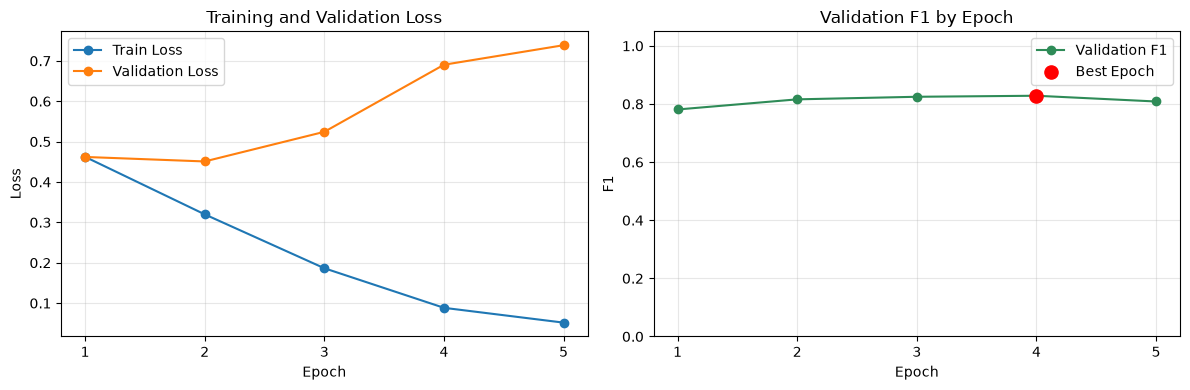

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train Loss",
)
axes[0].plot(
    history_df["epoch"],
    history_df["validation_loss"],
    marker="o",
    label="Validation Loss",
)
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    history_df["epoch"],
    history_df["validation_f1"],
    marker="o",
    color="seagreen",
    label="Validation F1",
)

best_row = history_df.loc[history_df["validation_f1"].idxmax()]
axes[1].scatter(
    best_row["epoch"],
    best_row["validation_f1"],
    color="red",
    s=90,
    label="Best Epoch",
    zorder=3,
)
axes[1].set_title("Validation F1 by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("F1")
axes[1].set_ylim(0, 1.05)
axes[1].legend()

for ax in axes:
    ax.set_xticks(history_df["epoch"])
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. 최적 모델로 테스트 평가
정밀도는 악성이라고 예측한 댓글 중 맞은 비율, 재현율은 실제 악성 댓글 중 찾아낸 비율입니다. F1은 둘의 균형을 나타냅니다. 확률 기준은 검증·테스트·예측 모두 0.5로 고정합니다.


In [16]:
# 학습에 사용한 모델을 해제하고 저장된 최적 모델을 읽습니다.
del optimizer, scheduler, model
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
elif DEVICE.type == "mps":
    torch.mps.empty_cache()
loaded_model = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR).to(DEVICE)
loaded_model.eval()
tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR)
experiment = json.loads((MODEL_DIR / "experiment.json").read_text(encoding="utf-8"))
MAX_LEN = experiment["max_len"]
THRESHOLD = experiment["threshold"]

test_metrics, test_true, test_probs = evaluate(loaded_model, test_dataloader, DEVICE, THRESHOLD)
test_pred = (test_probs >= THRESHOLD).astype(int)
print("최적 에폭:", experiment["best_epoch"])
print(pd.Series(test_metrics).round(4).to_string())
print(classification_report(test_true, test_pred, labels=[0, 1],
                            target_names=["일반 댓글", "악성 댓글"], zero_division=0))
display(pd.DataFrame(confusion_matrix(test_true, test_pred, labels=[0, 1]),
                     index=["실제 일반", "실제 악성"], columns=["예측 일반", "예측 악성"]))
(MODEL_DIR / "test_metrics.json").write_text(
    json.dumps(test_metrics, ensure_ascii=False, indent=2), encoding="utf-8"
)

# 오탐과 누락 사례를 살펴봅니다.
test_results = pd.DataFrame({"document": list(test["document"]), "label": test_true,
                             "prediction": test_pred, "malicious_probability": test_probs})
test_results.to_csv(MODEL_DIR / "test_predictions.csv", index=False, encoding="utf-8-sig")
display(test_results[test_results["label"] != test_results["prediction"]].head(10))


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 10844.97it/s]
                                                       

최적 에폭: 4
accuracy     0.8627
precision    0.8127
recall       0.7915
f1           0.8020
roc_auc      0.9132
loss         0.8097
              precision    recall  f1-score   support

       일반 댓글       0.89      0.90      0.89       567
       악성 댓글       0.81      0.79      0.80       307

    accuracy                           0.86       874
   macro avg       0.85      0.85      0.85       874
weighted avg       0.86      0.86      0.86       874



,예측 일반,예측 악성
실제 일반,511,56
실제 악성,64,243


,document,label,prediction,malicious_probability
3,이정도면 존못은 아닌듯,1,0,0.000494
9,ㅇㅇ 옛날처럼 깡패정국이 아닌이상 불체포특권도 없애야지.,0,1,0.998438
19,속보! ㅈ댔다! ㅋㅋㅋㅋㅋ ㅁㅈㅎ,0,1,0.985156
29,일베리스트 만들어서 한 10년정도 취업 안돼봐야 정신차림.,1,0,0.000479
36,영어하는 놈들이 왜 자살이야,0,1,0.998972
68,물론 일부 입니다 씨바,1,0,0.000330
79,농어촌특별전형이면 내신이 높고 수능이 낮은 거지내신 6~7이라 해샀노대구리 안돌아감?,0,1,0.926520
81,발기부전 냉동자지 에,1,0,0.002533
82,쪽국은 아직 시작도 안한셈..아마 제대로 검사시작하면 진정한 좀비국될듯...,0,1,0.998250
83,한걸레는 가난한 좃쭝똥일뿐입니다.,1,0,0.029065


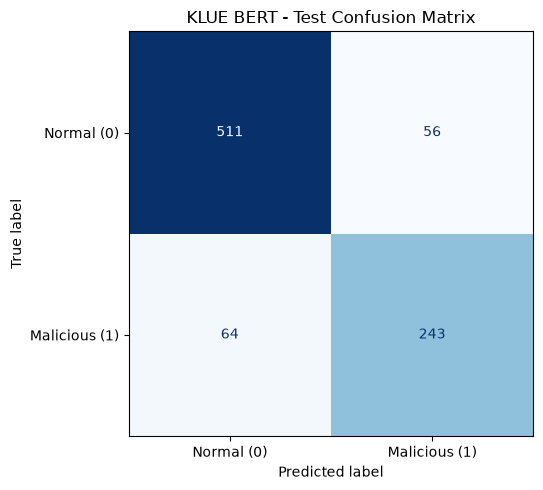

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(test_true, test_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal (0)", "Malicious (1)"],
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
)

ax.set_title("KLUE BERT - Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 6. 새 댓글 예측
아래 확률은 모델의 출력 점수이며 실제 악성 확률로 보정된 값은 아닙니다. 학습 데이터에 없던 표현과 문맥의 오류 사례를 확인해 보세요.


In [23]:
def prediction(text, threshold=THRESHOLD):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("비어 있지 않은 댓글 문자열을 입력하세요.")
    if not 0 <= threshold <= 1:
        raise ValueError("threshold는 0부터 1 사이여야 합니다.")
    encoded = tokenizer(text, truncation=True, max_length=MAX_LEN, return_tensors="pt")
    encoded = {key: value.to(DEVICE) for key, value in encoded.items()}
    loaded_model.eval()
    with torch.inference_mode():
        logits = loaded_model(**encoded).logits
        malicious_probability = torch.softmax(logits, dim=-1)[0, 1].item()
    label_id = int(malicious_probability >= threshold)
    return {"document": text, "label_id": label_id,
            "label": loaded_model.config.id2label[label_id],
            "malicious_probability": round(malicious_probability, 4)}

examples = ["오늘도 좋은 하루 보내세요.", "설명이 이해하기 쉬워요. 감사합니다.",
            "의견에는 동의하지 않지만 존중합니다.", "너 같은 멍청이는 입 다물어."]
display(pd.DataFrame([prediction(text) for text in examples]))
prediction("씨발 멍청한 새끼야 입 닥쳐")


,document,label_id,label,malicious_probability
0,오늘도 좋은 하루 보내세요.,0,일반 댓글,0.0002
1,설명이 이해하기 쉬워요. 감사합니다.,0,일반 댓글,0.0002
2,의견에는 동의하지 않지만 존중합니다.,0,일반 댓글,0.0002
3,너 같은 멍청이는 입 다물어.,1,악성 댓글,0.9995


{'document': '씨발 멍청한 새끼야 입 닥쳐',
 'label_id': 1,
 'label': '악성 댓글',
 'malicious_probability': 0.9995}